# DATA-445: Homework Assignment 8

**Instructions**

- This homework assignment is worth **88** points.
- Please submit a **.ipynb** file to Blackboard.
- **Please strive for clarity and organization.**
- **AI usage**:
  - AI use is strictly **prohibited** for conceptual exercises.
  - For applied (Python) exercises, you may use AI exclusively for **debugging**. Do not use AI to generate answers.
- **Due Date: November 13, 2026, by 11:59 PM.**

## Exercise 1 (9 points)

Principal component analysis (PCA) and linear discriminant analysis (LDA) are both linear techniques for dimensionality reduction.

**(a)** In your own words, state what objective each method optimizes, and explain why PCA is called *unsupervised* while LDA is called *supervised*.

**(b)** Describe a situation in which PCA would discard exactly the information that is most useful for classification, while LDA would keep it.

**(c)** For a classification problem with $c$ classes and $d$ features ($d > c$), what is the maximum number of linear discriminants LDA can produce? Explain why.

a. The PCA maximizes total variance while LDA maximizes class distance. PCA is called unsupervised because it functions on the feature matrix without using target labels. LDA is called supervised because it relies on the class labels and needs to know which variables belongs to which group to measure distance. 

b. Simply LDA keeps critical classification boundaries and PCA gets rid of them. PCA looks only for the direction of maximum overall variance which can get rid of class seperation if it runs parallel to groups that overlap. LDA uses class labels to maximize the distance between groups while also minimizing the space within. 

c.

## Exercise 2 (5 points)

Which of the following statements about nonlinear dimensionality reduction (t-SNE and UMAP) is **TRUE**?

**A.** The distances between well-separated clusters in a t-SNE plot faithfully reflect how dissimilar the clusters are in the original feature space.

**B.** t-SNE is a linear projection, so new observations can be mapped onto an existing embedding simply by multiplying them by a fixed projection matrix.

**C.** Perplexity in t-SNE (and `n_neighbors` in UMAP) controls roughly how many neighbors each point considers, so changing it can change the apparent structure of the plot; the plot should be inspected at several settings before drawing conclusions.

**D.** Because t-SNE and UMAP are deterministic, the resulting embedding is identical regardless of the random seed.

Select one answer and justify in one or two sentences why it is correct.

C would be the true statement. It is correct because these settings control how many nearby points the algorithm looks at to group data. Because changing them can completely change what the final plot looks like you should test a feew different settings before you actually trust the results.

## Exercise 3 (30 points)

In this exercise you will compare PCA, LDA, and t-SNE on the wine dataset (178 wines, 13 chemical features, 3 cultivars). Load it with:

```python
from sklearn.datasets import load_wine
X, y = load_wine(return_X_y=True, as_frame=True)
```

**(a)** Split the data into 70% training and 30% test sets (use `stratify = y` and `random_state = 1`). Standardize the features using the training set only.

**(b)** Fit PCA on the standardized training data keeping all 13 components. Plot the individual and cumulative explained variance ratios. How many components are needed to explain at least 90% of the variance?

**(c)** Reduce the data to **2 components** using PCA (fit on training data) and train a logistic regression on the result. Report the training and test accuracy.

**(d)** Repeat (c) using LDA with 2 components. Report the training and test accuracy, and make a scatter plot of the transformed training data colored by class for both PCA and LDA (side by side).

**(e)** Apply t-SNE (`perplexity = 30`, `random_state = 1`) to the full standardized dataset and plot the 2D embedding colored by class.

**(f)** In 2–3 sentences, compare the three methods based on your results. Which would you use for a classifier, and which only for visualization? Why?

In [ ]:
from sklearn.datasets import load_wine

X, y = load_wine(return_X_y=True, as_frame=True)


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=1)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

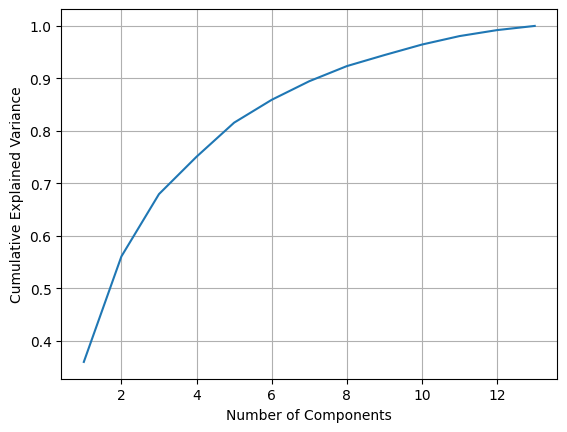

In [3]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt

pca = PCA()

X_train_pca = pca.fit_transform(X_train_scaled)


pca.explained_variance_ratio_
n_components = [i for i in range(1, X_train_scaled.shape[1] + 1)]

plt.plot(n_components, pca.explained_variance_ratio_.cumsum())
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.grid(True)
plt.show()


In [ ]:
# according to the graph about 7 components are needed to explain at least 90% of the variance

In [ ]:
#PCA 

from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression

pca2 = PCA(n_components=2)
x_train_pca2 = pca2.fit_transform(X_train_scaled)
x_test_pca2 = pca2.transform(X_test_scaled)

clf = LogisticRegression(random_state=1)
clf.fit(x_train_pca2, y_train)

y_train_pred = clf.predict(x_train_pca2)
y_test_pred = clf.predict(x_test_pca2)

train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)

print(f"Training Accuracy: {train_acc:.4f}")
print(f"Testing Accuracy: {test_acc:.4f}")



Training Accuracy: 0.9516
Testing Accuracy: 0.9815


PCA Testing Accuracy: 0.9815
LDA Testing Accuracy: 0.9630


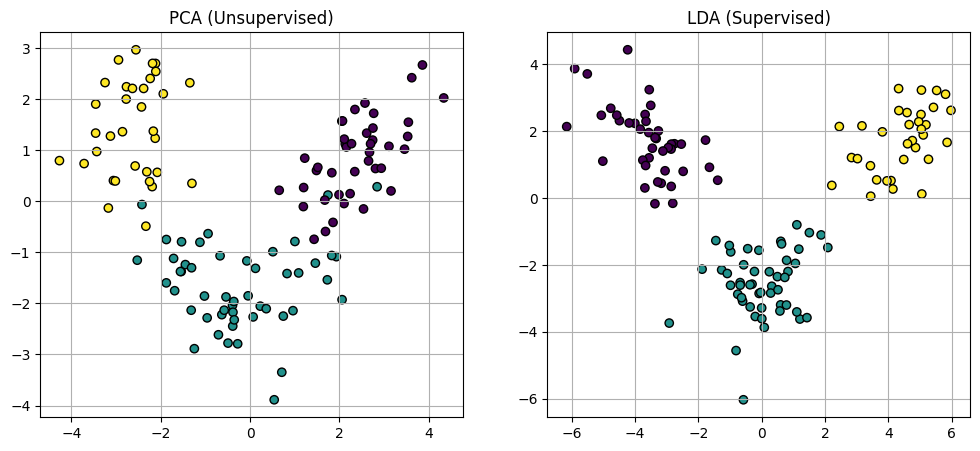

In [ ]:
#LDA

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
import matplotlib.pyplot as plt

lda = LinearDiscriminantAnalysis(n_components=2)
X_train_lda = lda.fit_transform(X_train_scaled, y_train)
X_test_lda = lda.transform(X_test_scaled)

clf_lda = LogisticRegression(random_state=1)
clf_lda.fit(X_train_lda, y_train)
lda_test = accuracy_score(y_test, clf_lda.predict(X_test_lda))

print(f"PCA Testing Accuracy: {test_acc:.4f}")
print(f"LDA Testing Accuracy: {lda_test:.4f}")

#Modeling with PCA and LDA
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train, cmap='viridis', edgecolors='k')
axes[0].set_title('PCA (Unsupervised)')
axes[0].grid(True)

axes[1].scatter(X_train_lda[:, 0], X_train_lda[:, 1], c=y_train, cmap='viridis', edgecolors='k')
axes[1].set_title('LDA (Supervised)')
axes[1].grid(True)

plt.show()

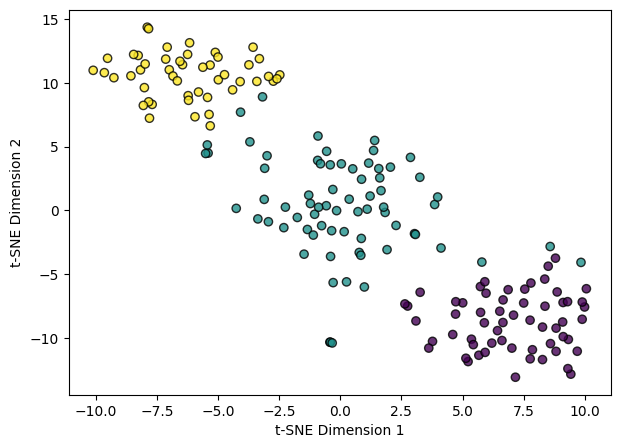

In [6]:
#TSNE

from sklearn.manifold import TSNE

X_scaled_full = scaler.fit_transform(X)
tsne = TSNE(n_components=2, random_state=1)
X_tsne = tsne.fit_transform(X_scaled_full)

plt.figure(figsize=(7, 5))
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y, cmap='viridis', edgecolors='k', alpha=0.8)
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')
plt.show()

In [ ]:
# PCA grabs overall data variance while LDA uses labels to seperate classes and t-SNE shows non-linear local clusters
# For a classifier i would use LDA or PCA because it can show new unseen test data.
# For visualizing i would use t-SNE because it cannot map new data points into the existing space.

## Exercise 4 (9 points)

A hospital builds a classifier to detect a rare disease that affects 5% of patients. The model achieves 95% accuracy on a test set that has the same 5% prevalence.

**(a)** What is the *null accuracy* in this problem? Explain why a 95% accuracy might say nothing about the usefulness of the model.

**(b)** Name two metrics (computed from the confusion matrix) that would be more informative here, give their formulas, and explain what each tells you about the rare class.

**(c)** A dataset has $n = 1000$ observations, of which 50 are positive. Compute the "balanced" class weights $w_j = \frac{n}{k\, n_j}$ for each class and explain what they accomplish.

a. The null accuracy is 0.95 and it might be misleading because the model could be missing all of actual sick patients while still seeming very accurate.
b. Two metrics that would be more helpful here were would be precision and recall. recall is TP/TP+FN and Precision is TP/TP+FP. Recall tells you out of all the patients who actually have the rare disease what percent is the model successfully predicting. Precision tells you out of all the patients who the model had as having the disease what percent actually have the disease. 
c.Positive class = 10
negative class = 0.53
There are higher penalties.Getting a rare case wrong costs the model more than getting a common case wrong which makes it learn how to classify the rare class. Also, because the rare cases are outnumbered these weights boost their importance and the model will actually pay attention.


## Exercise 5 (5 points)

A fraud-detection team assigns a cost of $C_{FP} = 2$ to every false positive (an unnecessary review) and $C_{FN} = 10$ to every false negative (a missed fraud). Assuming the model produces well-calibrated probabilities, which statement is **TRUE**?

**A.** The cost-optimal cutoff is $c^* = C_{FN}/(C_{FP}+C_{FN}) \approx 0.83$, so only very confident predictions should be flagged as fraud.

**B.** The cost-optimal cutoff is $c^* = C_{FP}/(C_{FP}+C_{FN}) \approx 0.17$, so transactions with predicted fraud probability above about 0.17 should be flagged.

**C.** The cost-optimal cutoff is 0.5 regardless of the costs, because the costs only matter during training.

**D.** ROC-AUC will change if we move the cutoff from 0.5 to 0.17, so ROC-AUC should be used to pick the cutoff.

Select one answer and justify it in one or two sentences.

b is true because missing fraud is more expensive than a false positive. To capture those mistakes you could lower the threshold to 17% probability which will flag transactions ealier.

## Exercise 6: (30 points)

In this exercise you will study classification on imbalanced data. Generate the data with:

```python
from sklearn.datasets import make_classification
X, y = make_classification(n_samples = 5000, n_features = 10, n_informative = 5,
                           weights = [0.92, 0.08], flip_y = 0.03, class_sep = 0.8,
                           random_state = 1)
```

Treat class 1 as the positive (event) class.

**(a)** Split the data into training (60%), validation (20%) and test (20%) sets using stratified sampling (`random_state = 1`). Report the proportion of positives in each set and the *null accuracy* on the test set.

**(b)** Fit a `RandomForestClassifier(n_estimators = 200, max_depth = 5, random_state = 1)` on the training set. On the test set (default cutoff 0.5) report accuracy, recall, precision, F1, balanced accuracy, ROC-AUC and PR-AUC.

**(c)** Refit the random forest with `class_weight = 'balanced'`. Report the same metrics on the test set (cutoff 0.5) and compare with (b).

**(d)** Suppose $C_{FP} = 1$ and $C_{FN} = 5$. Using the **baseline** model from (b), compute the total cost on the validation set for cutoffs from 0.01 to 0.99 (step 0.01), plot total cost vs. cutoff, and choose the cutoff with the smallest cost. Also compute the theoretical cutoff $c^* = C_{FP}/(C_{FP}+C_{FN})$.

**(e)** Apply the chosen cutoff to the test set and report the confusion matrix and total test cost. Compare it with the total cost of (i) the baseline model at cutoff 0.5, (ii) the "flag nobody" strategy and (iii) the "flag everybody" strategy.

**(f)** In 3–4 sentences, summarize what you learned: which approach (class weights vs. moving the cutoff) worked better in terms of cost, and why accuracy alone would have been misleading.

In [7]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

X, y = make_classification(n_samples=5000, n_features=10, n_informative=5, weights=[0.92, 0.08], flip_y=0.03, class_sep=0.8, random_state=1)

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, stratify=y, random_state=1)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=1
)

print(f"Train positive proportion: {y_train.mean():.4f} ({y_train.sum()}/{len(y_train)})")
print(f"Val positive proportion:   {y_val.mean():.4f} ({y_val.sum()}/{len(y_val)})")
print(f"Test positive proportion:  {y_test.mean():.4f} ({y_test.sum()}/{len(y_test)})")
print(f"Test null accuracy:        {1 - y_test.mean():.4f}")


Train positive proportion: 0.0910 (273/3000)
Val positive proportion:   0.0910 (91/1000)
Test positive proportion:  0.0910 (91/1000)
Test null accuracy:        0.9090


In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, recall_score, precision_score, f1_score,
    balanced_accuracy_score, roc_auc_score, average_precision_score
)

rf = RandomForestClassifier(n_estimators=200, max_depth=5, random_state=1)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)
y_prob = rf.predict_proba(X_test)[:, 1]

print(f"Accuracy:          {accuracy_score(y_test, y_pred):.4f}")
print(f"Recall:            {recall_score(y_test, y_pred):.4f}")
print(f"Precision:         {precision_score(y_test, y_pred):.4f}")
print(f"F1 Score:          {f1_score(y_test, y_pred):.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_test, y_pred):.4f}")
print(f"ROC-AUC:           {roc_auc_score(y_test, y_prob):.4f}")
print(f"PR-AUC:            {average_precision_score(y_test, y_prob):.4f}")


Accuracy:          0.9370
Recall:            0.3077
Precision:         1.0000
F1 Score:          0.4706
Balanced Accuracy: 0.6538
ROC-AUC:           0.9049
PR-AUC:            0.7784


In [10]:
rf_class = RandomForestClassifier(n_estimators=200, max_depth=5, class_weight='balanced', random_state=1)
rf_class.fit(X_train, y_train)

y_pred_bal = rf_class.predict(X_test)
y_prob_bal = rf_class.predict_proba(X_test)[:, 1]

print(f"Accuracy:          {accuracy_score(y_test, y_pred_bal):.4f}")
print(f"Recall:            {recall_score(y_test, y_pred_bal):.4f}")
print(f"Precision:         {precision_score(y_test, y_pred_bal):.4f}")
print(f"F1 Score:          {f1_score(y_test, y_pred_bal):.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_test, y_pred_bal):.4f}")
print(f"ROC-AUC:           {roc_auc_score(y_test, y_prob_bal):.4f}")
print(f"PR-AUC:            {average_precision_score(y_test, y_prob_bal):.4f}")

Accuracy:          0.9130
Recall:            0.7582
Precision:         0.5149
F1 Score:          0.6133
Balanced Accuracy: 0.8434
ROC-AUC:           0.8925
PR-AUC:            0.7431


Minimum Validation Cost: 164
Empirical Optimal Cutoff(s): [0.14 0.15 0.17] (first minimum: 0.14)
Theoretical Cutoff c*: 0.1667


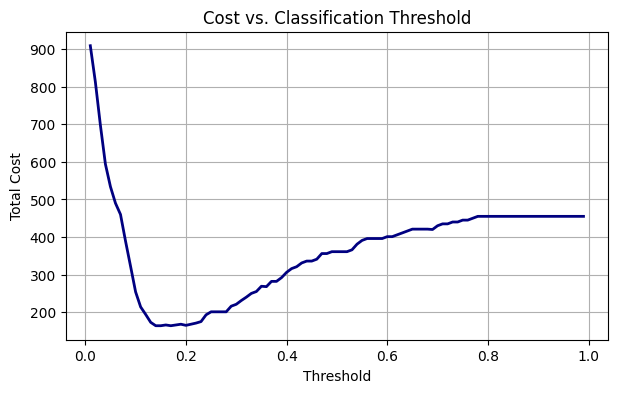

In [12]:
from sklearn.metrics import confusion_matrix
import numpy as np

val = rf.predict_proba(X_val)[:,1]
cutoffs = np.arange(0.01, 1.00, 0.01)

c_fp = 1
c_fn = 5
costs = []

for i in cutoffs:
    preds = (val >= i).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, preds).ravel()
    total_cost = c_fp * fp + c_fn * fn
    costs.append(total_cost)

costs = np.array(costs)

min_cost = costs.min()
best_cutoffs = cutoffs[costs == min_cost]
best_cutoff = best_cutoffs[0]  
c_star = c_fp / (c_fp + c_fn)

print(f"Minimum Validation Cost: {min_cost}")
print(f"Empirical Optimal Cutoff(s): {best_cutoffs} (first minimum: {best_cutoff:.2f})")
print(f"Theoretical Cutoff c*: {c_star:.4f}")

plt.figure(figsize=(7, 4))
plt.plot(cutoffs, costs, color='navy', linewidth=2)
plt.title('Cost vs. Classification Threshold')
plt.xlabel('Threshold')
plt.ylabel('Total Cost')
plt.grid(True)
plt.show()


In [14]:
test_probs = rf.predict_proba(X_test)[:,1]
c_fp, c_fn = 1, 5

strategies = {
    "Chosen Cutoff (0.14)": (test_probs >= 0.14).astype(int),
    "Baseline Cutoff (0.50)": (test_probs >= 0.50).astype(int),
    "Flag Nobody": np.zeros_like(y_test),
    "Flag Everybody": np.ones_like(y_test)
}

for name, preds in strategies.items():
    tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()
    cost = (c_fp * fp) + (c_fn * fn)
    print(f"{name}")
    print(f"Confusion Matrix: TN={tn}, FP={fp}, FN={fn}, TP={tp}")
    print(f"Total Cost: {cost}\n")

Chosen Cutoff (0.14)
Confusion Matrix: TN=855, FP=54, FN=20, TP=71
Total Cost: 154

Baseline Cutoff (0.50)
Confusion Matrix: TN=909, FP=0, FN=63, TP=28
Total Cost: 315

Flag Nobody
Confusion Matrix: TN=909, FP=0, FN=91, TP=0
Total Cost: 455

Flag Everybody
Confusion Matrix: TN=0, FP=909, FN=0, TP=91
Total Cost: 909



When you lower the decision threshold to match real world costs it was shown to work best. It cut total test costs in half to 154. Accuracy by itself is not a good metric to look at because flag nobody gives a really high 90.9% score but its misses important information and is very costly. By changing thresholds based on expenses is a better approach for imbalanced data. 